In [5]:

import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from typing import Literal
from pydantic import BaseModel, Field
from google import genai


# ---------------- CONFIGURATION ----------------

IMAGE_PATH = Path("map.jpg")
OUTPUT_PATH = Path("hogwarts_map.json")
MASK_PREVIEW_PATH = Path("walkability_preview.png")

# Higher resolution preserves more detail but creates a larger graph.
GRID_WIDTH = 400

# Assumption: the floor is lighter than the walls.
# Set False if the walls are lighter than the floor.
LIGHT_FLOOR = True


# ---------------- GEMINI SCHEMA ----------------

class Location(BaseModel):
    id: str = Field(description="Unique lowercase ID with underscores")
    name: str
    type: Literal[
        "room", "corridor", "stair",
        "junction", "entrance", "other"
    ]
    x: float = Field(description="Horizontal position, 0-100 percent")
    y: float = Field(description="Vertical position, 0-100 percent")
    confidence: float
    notes: str


class MapFeatures(BaseModel):
    locations: list[Location]


# ---------------- LOAD MAP ----------------

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Cannot find {IMAGE_PATH.resolve()}")

image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise ValueError("Could not read the image. Check its format.")

height, width = image.shape[:2]

print(f"Loaded map: {width} x {height} pixels")


# ---------------- DETECT LOCATIONS WITH GEMINI ----------------

client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

image_bytes = IMAGE_PATH.read_bytes()

prompt = """
Analyse this architectural Hogwarts floor plan.

Identify every clearly visible named room and useful navigation
location, including corridor junctions, stairs and entrances.

For each location:
- Give a unique lowercase ID using underscores.
- Give its visible name.
- Classify its type.
- Estimate the centre of the actual room or location.
- Express x and y as percentages of the ORIGINAL image.
- x=0 is the left edge; x=100 is the right edge.
- y=0 is the top edge; y=100 is the bottom edge.
- Give a confidence score between 0 and 1.
- Explain uncertainty in notes.

Do not invent names or connections.
Coordinates must refer to the original image.
Do not return wall or corridor geometry; only locations.
"""

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=[
        prompt,
        genai.types.Part.from_bytes(
            data=image_bytes,
            mime_type="image/jpeg",
        ),
    ],
    config={
        "response_mime_type": "application/json",
        "response_schema": MapFeatures,
    },
)

if not response.text:
    raise RuntimeError("Gemini returned no location data.")

features = MapFeatures.model_validate_json(response.text)

# Validate coordinates before using them.
locations = []

for loc in features.locations:
    if not (0 <= loc.x <= 100 and 0 <= loc.y <= 100):
        print(f"Skipping out-of-bounds location: {loc.name}")
        continue

    locations.append(loc.model_dump())

print(f"Gemini detected {len(locations)} locations.")


# ---------------- CREATE CANDIDATE WALKABILITY MASK ----------------

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Otsu thresholding separates dark and light pixels.
# This works best for high-contrast architectural floor plans.
threshold_type = (
    cv2.THRESH_BINARY
    if LIGHT_FLOOR
    else cv2.THRESH_BINARY_INV
)

_, binary = cv2.threshold(
    gray,
    0,
    255,
    threshold_type + cv2.THRESH_OTSU,
)

# 255 = candidate walkable pixel; 0 = candidate obstacle.
# This is an initial estimate, not guaranteed wall detection.
walkable_full = binary > 0

# Downsample to a manageable grid.
grid_height = max(
    1, round(height * GRID_WIDTH / width)
)

# Area interpolation records the proportion of light pixels
# within each grid cell. A threshold of 0.5 is a starting point.
coverage = cv2.resize(
    walkable_full.astype(np.float32),
    (GRID_WIDTH, grid_height),
    interpolation=cv2.INTER_AREA,
)

walkable_grid = coverage >= 0.5

# Store each grid row as a string of 0s and 1s.
# This is compact and easy to load from JSON.
grid_rows = [
    "".join("1" if cell else "0" for cell in row)
    for row in walkable_grid
]


# ---------------- SAVE MASK PREVIEW ----------------

plt.figure(figsize=(14, 10))
plt.imshow(walkable_grid, cmap="gray", origin="upper")
plt.title("Candidate Walkability Mask (white = walkable)")
plt.axis("off")
plt.tight_layout()
plt.savefig(MASK_PREVIEW_PATH, dpi=180)
plt.close()

print(f"Saved candidate mask preview: {MASK_PREVIEW_PATH}")


# ---------------- SAVE UNIFIED JSON ----------------

output = {
    "metadata": {
        "source_image": IMAGE_PATH.name,
        "image_width": width,
        "image_height": height,
        "grid_width": GRID_WIDTH,
        "grid_height": grid_height,
        "coordinate_system": "percentage; origin at top-left",
        "walkability_encoding": {
            "1": "candidate walkable cell",
            "0": "candidate blocked cell",
        },
        "mask_status": "automatic candidate; requires verification",
    },
    "locations": locations,
    "walkability": grid_rows,
}

OUTPUT_PATH.write_text(
    json.dumps(output, indent=2),
    encoding="utf-8",
)

print(f"Saved {OUTPUT_PATH}")
print(f"Grid dimensions: {GRID_WIDTH} x {grid_height}")

ModuleNotFoundError: No module named 'cv2'

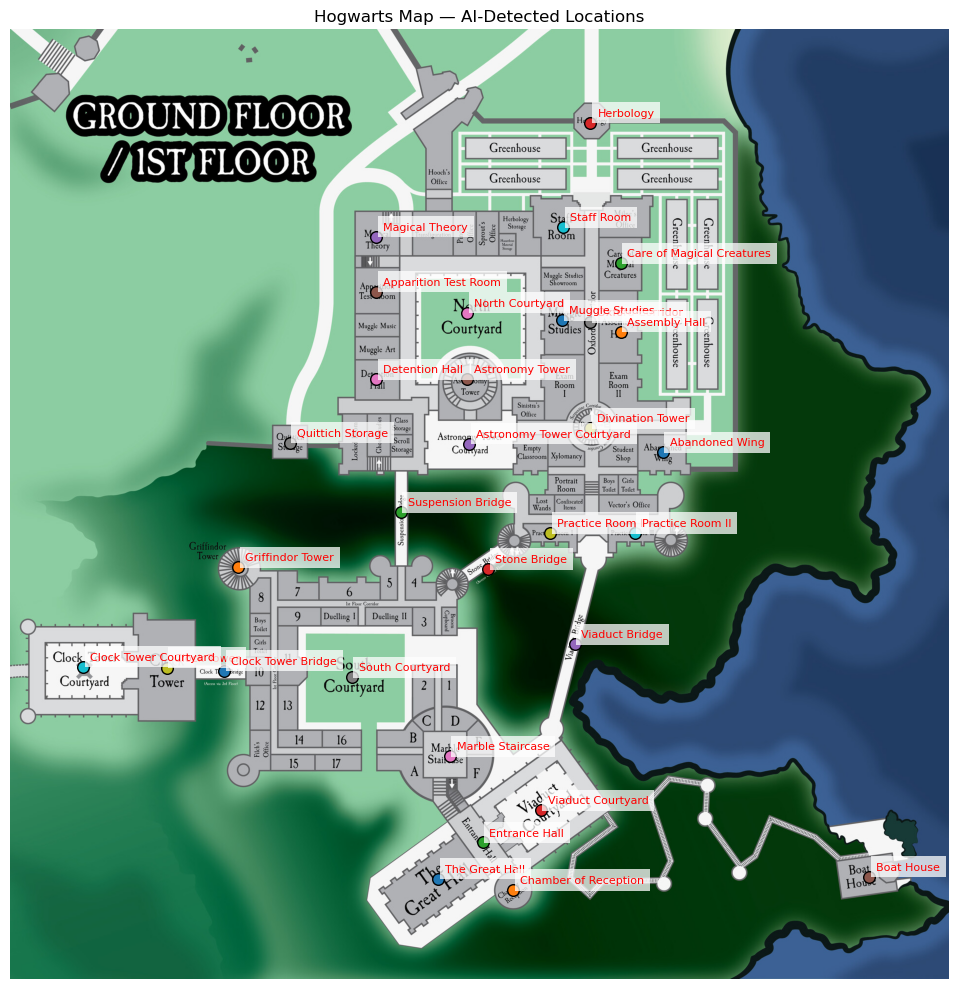

Visualised 31 locations.
Saved annotated map to hogwarts_annotated.png


In [3]:

import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load the map image
image = mpimg.imread("map.jpg")

# Load Gemini's detected locations
with open("map_features.json", "r", encoding="utf-8") as f:
    data = json.load(f)

locations = data["locations"]

height, width = image.shape[:2]

fig, ax = plt.subplots(figsize=(14, 10))
ax.imshow(image)

# Plot each detected location
for loc in locations:
    # Convert percentages to image pixel coordinates
    x = loc["x"] / 100 * width
    y = loc["y"] / 100 * height

    # Mark the location
    ax.scatter(x, y, s=70, marker="o", edgecolors="black")

    # Add its name next to the marker
    ax.annotate(
        loc["name"],
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
        color="red",
        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"),
    )

ax.set_title("Hogwarts Map — AI-Detected Locations")
ax.axis("off")

plt.tight_layout()
plt.savefig("hogwarts_annotated.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Visualised {len(locations)} locations.")
print("Saved annotated map to hogwarts_annotated.png")
